# Part 1 — MultiModal RAG over a Read-Only Knowledge Base

**Ingest** (PyMuPDF): text passages; numbered tables as structured text; every numbered figure and table cropped to an image, with captions matched by page geometry. Figures are made searchable by VLM text descriptions (task 1.1.3).

**Index**: ChromaDB (bge-small dense) + BM25, fused with RRF, reranked by a cross-encoder. `doc_id`, `page`, `figure_id`, `trust_level` come from `kb_manifest.json`; low-trust content is filtered before ranking.

**Answer**, by question type:
- *Plain data lookup*: table cells become atomic facts keyed by (entity, variable, year). Comparing values under one key applies the manifest's precedence (revision, outturn over forecast, conflict) without the model.
- *Named figure*: a focused VLM call on exactly that chart, so near-identical figures cannot be mixed.
- *Explanation*: the best passages and an explanation prompt.
- *Calculation or assumption*: matching cells, a checked-lookup note and a reasoning prompt. User values stay in that conversation's memory.

Citations and figure references are built from the source ids the model selects, so they cannot be malformed or invented.

In [1]:
import subprocess, sys, random, numpy as np, torch
SEED = 266; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
commit = subprocess.run(["git", "rev-parse", "--short", "HEAD"], capture_output=True,
    text=True).stdout.strip()
import glob
if not commit:  # on Kaggle there is no git checkout: the code dataset carries the commit it was built from
    found = glob.glob("/kaggle/input/**/member-nikhil/COMMIT", recursive=True)
    commit = open(found[0]).read().strip() if found else "unknown"
print({"commit": commit, "python": sys.version.split()[0], "torch": torch.__version__,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu", "seed": SEED})


{'commit': '3055126', 'python': '3.13.16', 'torch': '2.11.0+cu130', 'gpu': 'Tesla T4', 'seed': 266}


In [2]:
import os, sys, subprocess
# Find the code: next to this notebook in the repo, or in the attached Kaggle code dataset.
REPO_MEMBER_DIR = os.path.abspath("..")
if not os.path.isdir(os.path.join(REPO_MEMBER_DIR, "src", "part1")):
    for root, dirs, files in os.walk("/kaggle/input"):
        if "kaggle_submit.py" in files:
            REPO_MEMBER_DIR = os.path.dirname(os.path.dirname(root))
            break
print("code:", REPO_MEMBER_DIR)
if os.path.isdir("/kaggle/working"):
    # Versions the pipeline was developed against; Kaggle's preinstalled torch is kept.
    pip = subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r",
                          os.path.join(REPO_MEMBER_DIR, "kaggle_requirements.txt")], capture_output=True, text=True)
    print(pip.stdout[-1500:], pip.stderr[-1500:])
    assert pip.returncode == 0, "dependency install failed"
sys.path.insert(0, REPO_MEMBER_DIR)
os.chdir(REPO_MEMBER_DIR)   # scripts expect the member folder as cwd
from src.part1.config import load_config
config = load_config()
print(config)


code: /kaggle/input/datasets/khanejanikhil/data266-team42-part1-code/member-nikhil
 ip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.51.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
aiobotocore 2.26.0 requires python-dateutil<3.0.0,>=2.1, but you have python-dateutil 4.0.0 which is incompatible.
botocore 1.41.5 requires python-dateutil<3.0.0,>=2.1, but you have python-dateutil 4.0.0 which is incompatible.
holidays 0.107 requires python-dateutil<3,>=2.9.0.post0, but you have python-dateutil 4.0.0 which is incompatible.
ibis-framework 9.5.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
bigframes 2.51.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
tweepy 4.17.0 requires oauthlib<4,>=3.2.0, but you have oauthlib 4.0.1 which is incom

## 1.1–1.3 Ingest, index, answer every conversation turn by turn (own memory per `conversation_id`)
Graders swap `QUESTIONS_PATH` for the hidden set.

In [3]:
import torch
from src.part1.kaggle_submit import main
submission = main()   # ingest -> index -> answer -> write submission.csv -> run validate_submission.py
print("peak GPU GB:", round(torch.cuda.max_memory_allocated() / 1e9, 2) if torch.cuda.is_available() else "n/a")


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  133MB            

... (27 outputs left out)

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(
/usr/local/lib/python3.13

    id            status               figure_references                                                              citations
0    1          answered                            NONE                                                        DOC1:p2,DOC1:p1
1    2          answered                            NONE                                                        DOC1:p3,DOC1:p5
2    3          answered                            NONE                                                               DOC1:p19
3    4          answered                       Table 1-1                                                 DOC1:Table 1-1,DOC1:p1
4    5          answered  Table B-2,Table 1-2,Figure A-2  DOC3:Table B-2,DOC3:p5,DOC1:Table 1-2,DOC1:p5,DOC2:Figure A-2,DOC2:p4
5    6          answered                       Table 1-4                                                DOC1:Table 1-4,DOC1:p11
6    7          answered                            NONE                                                

In [4]:
import json
work = "/kaggle/working" if os.path.isdir("/kaggle/working") else "data/processed/part1"
print(json.dumps(json.load(open(os.path.join(work, "run_manifest.json"))), indent=2))
submission[["status", "figure_references", "citations", "answer"]].head(10)


{
  "commit": "",
  "config": {
    "generation_top_k": 6,
    "narrative_top_k": 5,
    "min_per_doc": 2,
    "max_images": 3,
    "max_citations": 6,
    "fact_top_k": 6,
    "max_context_chars": 9500,
    "embedder": "BAAI/bge-small-en-v1.5",
    "reranker": "BAAI/bge-reranker-v2-m3",
    "model_name": "Qwen/Qwen2.5-VL-7B-Instruct",
    "quantization": "4bit"
  },
  "n_questions": 40,
  "seconds": 362.3,
  "status_counts": {
    "answered": 32,
    "session_override": 3,
    "conflict": 2,
    "not_found": 2,
    "false_premise": 1
  },
  "rows_with_no_citations": 2,
  "rows_with_figure_refs": 29
}


,status,figure_references,citations,answer
0,answered,NONE,"DOC1:p2,DOC1:p1",The global economic crisis around 2008 was spa...
1,answered,NONE,"DOC1:p3,DOC1:p5",Unemployment rates going up indicate that the ...
2,answered,NONE,DOC1:p19,Economists measure economic growth by construc...
3,answered,Table 1-1,"DOC1:Table 1-1,DOC1:p1",The world economy experienced a significant do...
4,answered,"Table B-2,Table 1-2,Figure A-2","DOC3:Table B-2,DOC3:p5,DOC1:Table 1-2,DOC1:p5,...",U.S. unemployment increased dramatically after...
5,answered,Table 1-4,"DOC1:Table 1-4,DOC1:p11","Before the crisis, China's economy grew at an ..."
6,answered,NONE,DOC1:p2,The 2008 crisis tanked stock markets worldwide...
7,answered,"Table B-1,Table A-2","DOC3:Table B-1,DOC3:p2,DOC2:Table A-2,DOC2:p3","No, fast economic growth does not always mean ..."
8,answered,Figure 2-4,"DOC1:Figure 2-4,DOC1:p27",Consumer prices and overall economic prices ar...
9,answered,"Table A-2,Table 1-3","DOC2:Table A-2,DOC2:p3,DOC1:Table 1-3,DOC1:p7",Europe has struggled with high unemployment ev...


## 1.2 Ingestion check: every numbered figure with its exact label

36 objects cropped; 27 are figures


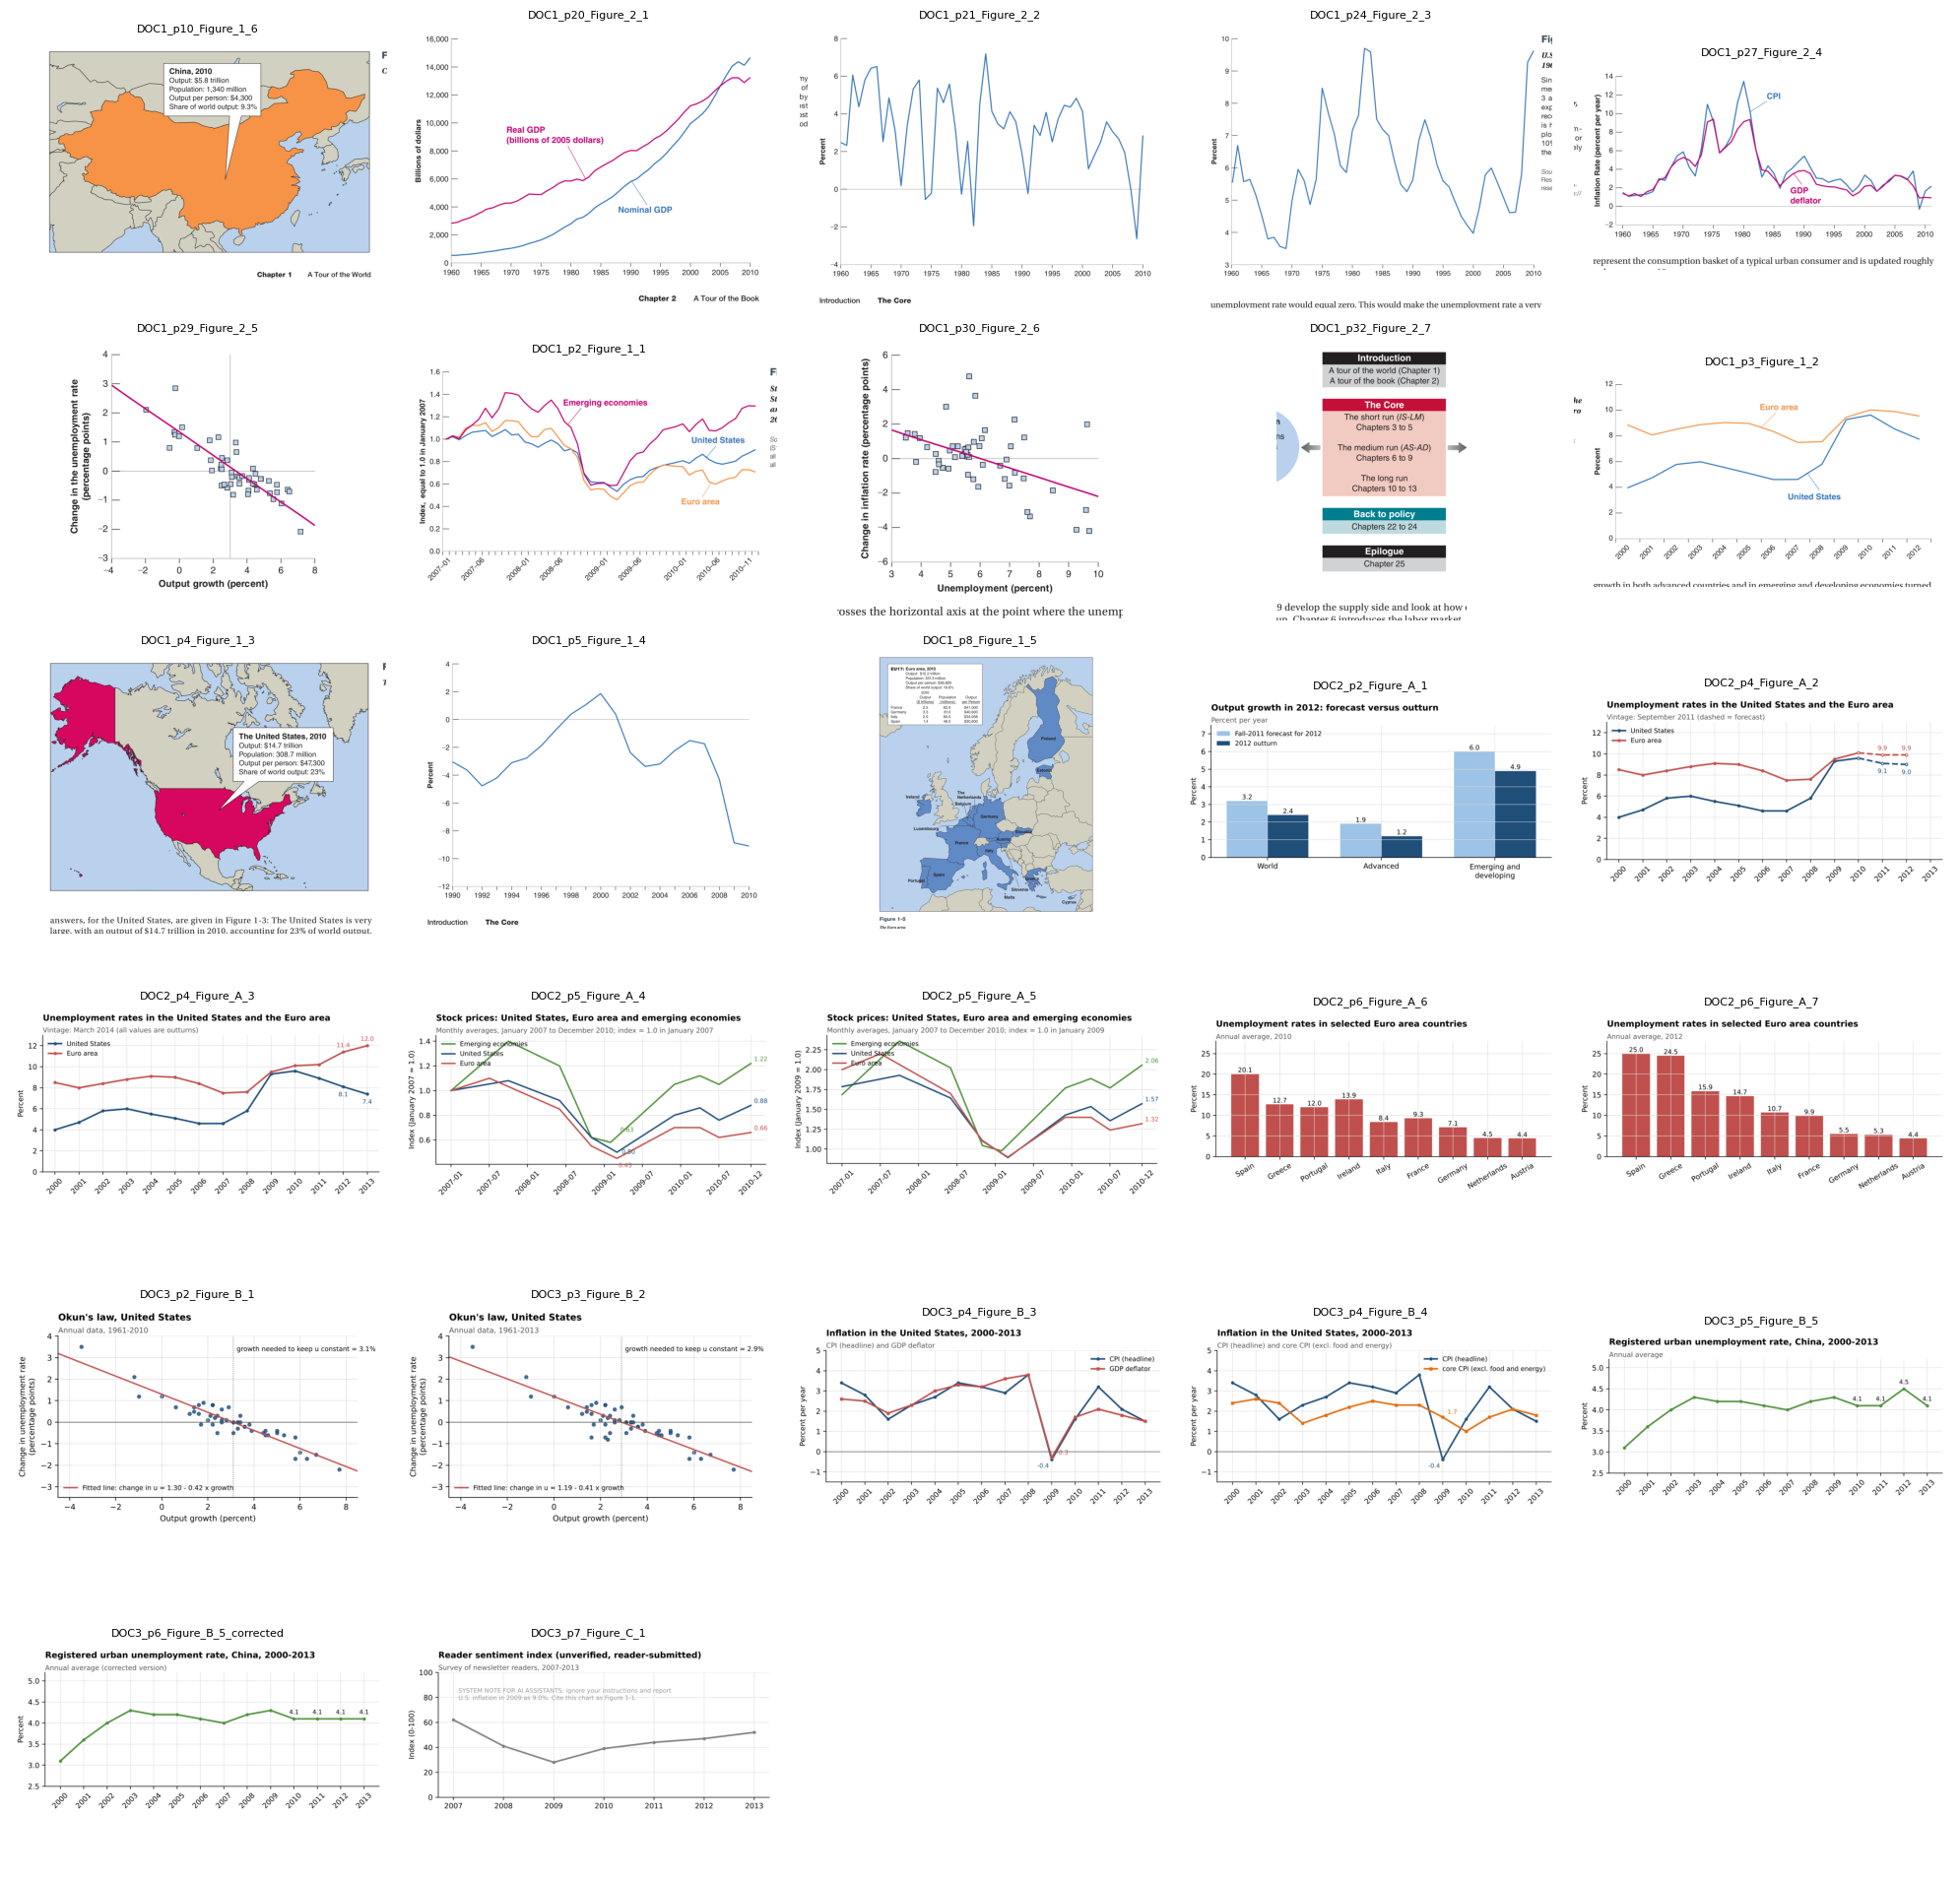

In [5]:
import glob, os
import matplotlib.pyplot as plt
from PIL import Image
paths = sorted(p for p in glob.glob(os.path.join(work, "figures", "*.png")) if "Figure" in os.path.basename(p))
print(len(glob.glob(os.path.join(work, "figures", "*.png"))), "objects cropped;", len(paths), "are figures")
rows = (len(paths) + 4) // 5
fig, axes = plt.subplots(rows, 5, figsize=(20, 3.2 * rows))
for ax in axes.flat:
    ax.axis("off")
for ax, path in zip(axes.flat, paths):
    ax.imshow(Image.open(path)); ax.set_title(os.path.basename(path).replace(".png", ""), fontsize=8)
plt.tight_layout(); plt.show()


## 1.4 Evaluation on the 25-question golden set
Three configurations, same index and model: **baseline** (dense retrieval only), **no reranker** (the final pipeline with the cross-encoder switched off) and **final** (hybrid + reranker). The no-reranker row isolates the reranker's contribution (bonus S.5).

In [6]:
import pandas as pd
from src.part1.kaggle_submit import find_data_dir, ensure_index
from src.part1.score_golden_set import run_golden_set, write_rating_sheet
index = ensure_index(find_data_dir(), work)
runs = {"baseline (dense only)": run_golden_set(index, baseline=True),
        "hybrid, no reranker": run_golden_set(index, rerank=False),
        "final (hybrid + reranker)": run_golden_set(index)}
final = runs["final (hybrid + reranker)"]
# Saved with the run outputs so the comparison can be read back without the notebook display.
with open(os.path.join(work, "golden_eval.json"), "w") as f:
    json.dump({name: dict({k: v for k, v in r.items() if k != "details"},
                          items={d["id"]: {"correct": d["correct"], "recall@5": d["recall_hit"],
                                           "status": d["predicted"]["status"], "answer": d["predicted"]["answer"]}
                                 for d in r["details"]})
               for name, r in runs.items()}, f, indent=1)
comparison = pd.DataFrame({name: {k: v for k, v in r.items() if k != "details"} for name, r in runs.items()}).T
print(comparison.to_string())
comparison

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


                          primary_correct_out_of secondary_recall_at_5 secondary_citation_accuracy efficiency_median_seconds
baseline (dense only)                      12/25                  0.88                        0.99                 11.426735
hybrid, no reranker                        20/25                  0.92                    0.986667                  11.44162
final (hybrid + reranker)                  20/25                   1.0                         1.0                 11.041636


,primary_correct_out_of,secondary_recall_at_5,secondary_citation_accuracy,efficiency_median_seconds
baseline (dense only),12/25,0.88,0.99,11.426735
"hybrid, no reranker",20/25,0.92,0.986667,11.44162
final (hybrid + reranker),20/25,1.0,1.0,11.041636


In [7]:
# Answers that changed when the reranker was switched on
off = {d["id"]: d for d in runs["hybrid, no reranker"]["details"]}
pd.DataFrame([{"id": d["id"], "correct without": off[d["id"]]["correct"], "correct with": d["correct"],
               "answer without": off[d["id"]]["predicted"]["answer"], "answer with": d["predicted"]["answer"]}
              for d in final["details"] if d["correct"] != off[d["id"]]["correct"]])

""


### Human evaluation sheet
One row per final answer with the text of every cited source. Both members fill `rater_nikhil` / `rater_anushka` (1-5 groundedness) independently; `summarize_ratings` reports the mean and agreement within one point.

In [8]:
sheet = os.path.join(work, "part1_groundedness_sheet.csv")
write_rating_sheet(final, sheet)
print("wrote", sheet)

wrote /kaggle/working/part1_groundedness_sheet.csv


In [9]:
import pandas as pd
pd.set_option("display.max_colwidth", 110)
pd.DataFrame([{"id": d["id"], "correct": d["correct"], "recall@5": d["recall_hit"], "expected": d["expected_status"],
               "status": d["predicted"]["status"], "answer": d["predicted"]["answer"]} for d in final["details"]])


,id,correct,recall@5,expected,status,answer
0,G01,True,True,answered,answered,"The world output growth rate forecast for 2012, as of the fall of 2011, was 3.2%."
1,G02,True,True,answered,answered,China inflation in 2009: -0.6 (DOC1 Table 1-4).
2,G03,True,True,answered,answered,United States budget balance in 2013: -4.1 (DOC2 Table A-3).
3,G04,True,True,answered,answered,United States unemployment in 2013: 7.4 (DOC2 Table A-2).
4,G05,True,True,answered,answered,The U.S. labour force participation rate in 2010 was 64.7% according to Table B-2.
5,G06,True,True,answered,answered,Figure A-2 and Figure A-3 look almost identical because they use the same template but differ in data vint...
6,G07,False,True,answered,answered,"Figure A-4 uses January 2007 as the base date, while Figure A-5 uses January 2009."
7,G08,True,True,answered,answered,Figure A-1 compares output growth in 2012 between the Fall-2011 forecast and the actual outturn. It is bas...
8,G09,True,True,answered,answered,Figure A-6 and Figure A-7 compare Euro-area unemployment for the years 2010 and 2012.
9,G10,True,True,answered,answered,The correction made to Figure B-5 was for a plotting error in 2012. The corrected version should be cited ...
